# 01 — SKAB data assessment
**Question:** what can these recordings support before we fit an anomaly detector?

SKAB contains sensor measurements from a physical water-circulation testbed with controlled interventions.
We assess all eight measurement channels, their timing, distributions, dependence and annotations.
This is an exploration notebook: no detector, fitted normalisation, alert threshold or performance claim is produced.

**Boundaries.** The source manifest reserves eight complete experiments before value exploration. We open
26 development experiments and the separate anomaly-free recording only. This is our experiment holdout,
not an official benchmark split or a chronological future test. All recordings come from one testbed;
they are not 35 independent industrial assets. Do not concatenate files into one continuous time series.

The [source documentation](https://github.com/waico/SKAB/tree/b2c0d46c2971dcbfe71e26087b6d231998bb91c2)
and [experiment descriptions](https://github.com/waico/SKAB/blob/b2c0d46c2971dcbfe71e26087b6d231998bb91c2/data/README.md)
define the measurement meanings and intended interventions. Actual CSV contents determine the audit.

In [1]:
from pathlib import Path
from dataclasses import asdict
import json
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from ts_anomaly.skab import METRICS, load_development, initial_normal
from ts_anomaly.assessment import (
    sampling_report, duplicate_report, bin_coverage, signal_profile,
    state_runs, aggregate_gauges, segment_acf, relationship_report,
)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "configs/skab.json").exists(), "Open the repository or its notebooks folder."
settings = json.loads((ROOT / "configs/skab.json").read_text())
OUTPUT = ROOT / "outputs/skab_assessment"
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 3.5), "axes.grid": True, "grid.alpha": .18})
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 40)
pd.set_option("display.max_colwidth", None)
names = list(METRICS)
units = {name: definition.unit for name, definition in METRICS.items()}
manifest = pd.DataFrame(settings["files"])
manifest["family"] = manifest.recording_id.str.split("/").str[0]
display(pd.crosstab(manifest.family, manifest.partition))
print("Source commit:", settings["source_commit"])
print("Reserved IDs:", ", ".join(manifest.loc[manifest.partition.eq("reserved_test"), "recording_id"]))

partition,development,reference,reserved_test
family,,,
anomaly-free,0,1,0
other,11,0,3
valve1,12,0,4
valve2,3,0,1


Source commit: b2c0d46c2971dcbfe71e26087b6d231998bb91c2
Reserved IDs: other/12, other/4, other/8, valve1/11, valve1/15, valve1/3, valve1/7, valve2/3


## 1. Measurements and source loading
Think of an electric motor driving a pump that circulates water. We observe vibration, electricity,
pressure, flow and temperature. Changes can indicate altered operating conditions as well as faults;
a single channel does not identify the cause.

There are **eight numerical measurements and two annotation columns**, not eight analogue plus digital
control channels. The annotations are kept in separate tables. RMS is an amplitude summary, so these
data do not provide the original high-frequency vibration waveform. No documented operating-command
signals are available.

The reader preserves source names and values. In this notebook, `entity_id` identifies a recording so
generic functions never join separate experiments; it does not imply a different machine.
The timezone is unknown and is not converted to UTC.

Source families: **valve1** restricts the pump inlet; **valve2** restricts the outlet.
**other** covers fluid additions/leaks, rotor imbalance, cavitation and warmer fluid.
These are intended interventions, not observed operating-state measurements.

In [2]:
dictionary = pd.DataFrame({name: asdict(definition) for name, definition in METRICS.items()}).T
display(dictionary[["description", "unit", "kind", "note"]])

# The loader verifies pinned source bytes and never opens reserved test files.
recordings, annotations = load_development(ROOT / "data/skab", settings)
reserved = set(manifest.loc[manifest.partition.eq("reserved_test"), "recording_id"])
assert not reserved.intersection(recordings)
assert all(not {"anomaly", "changepoint"}.intersection(frame.columns) for frame in recordings.values())
data = pd.concat(recordings.values(), ignore_index=True)
print(f"Opened {len(recordings)} recordings: {len(data):,} rows, {len(names)} measurement columns.")
print(f"Separate annotation tables: {len(annotations)}. Timezone: {data.timestamp.dt.tz}.")

,description,unit,kind,note
Accelerometer1RMS,"Vibration acceleration, sensor 1 (RMS)",g,gauge,Amplitude summary; raw vibration frequencies cannot be recovered.
Accelerometer2RMS,"Vibration acceleration, sensor 2 (RMS)",g,gauge,A second vibration channel; location and axis are not specified.
Current,Electric motor current,A,gauge,Changes may reflect motor load or electrical behaviour.
Pressure,Loop pressure after the pump,bar,gauge,Pressure reference and calibrated limits are unspecified; retain negatives.
Temperature,Motor body temperature,degC,gauge,Thermal history and operating conditions can affect this signal.
Thermocouple,Circulating fluid temperature,degC,gauge,A different thermal location from the motor body.
Voltage,Electric motor voltage,V,gauge,Supply changes can accompany changes in current.
Volume Flow RateRMS,Circulating fluid flow rate,L/min,gauge,Named RateRMS in the README; preserve the actual CSV column name.


Opened 27 recordings: 37,892 rows, 8 measurement columns.
Separate annotation tables: 26. Timezone: None.


## 2. Timing and data quality
**Question:** are missing values absent, or are observations themselves missing?

We audit acquisition order before sorting. A nominal one-second interval is a reference for describing
timing, not permission to fill a regular grid. A gap longer than two seconds is flagged for inspection;
this threshold accommodates the frequent one/two-second spacing, but does not establish continuity of
the physical process. One-second ACF calculations below are stricter and break at every missing second.

Within each observed first-to-last timestamp span, we also count occupied one-second bins.
This measures recording occupancy, not uptime, and makes no claim about time before or after a file.

In [3]:
timing, intervals, gaps = sampling_report(data, settings["gap_threshold"])
timing["span_minutes"] = (timing.end - timing.start).dt.total_seconds() / 60
occupancy = []
for identifier, frame in recordings.items():
    bins = bin_coverage(frame.timestamp, frame.timestamp.min(),
                        frame.timestamp.max() + pd.Timedelta(seconds=1), "1s")
    occupancy.append({"entity_id": identifier, "second_bins": len(bins),
                      "occupied_seconds": int(bins.occupied.sum()),
                      "second_occupancy": bins.occupied.mean()})
timing = timing.merge(pd.DataFrame(occupancy), on="entity_id")
display(timing[["entity_id", "rows", "span_minutes", "median_interval_s",
                "max_interval_s", "gaps", "second_occupancy"]].round(3))
display(intervals.groupby("interval_s")["count"].sum().rename("intervals").to_frame())
display(gaps.nlargest(6, "elapsed_s").reset_index(drop=True))
duplicates = duplicate_report(data, names)
profiles = signal_profile(data, METRICS)
quality = profiles.groupby("measurement").agg(
    missing=("missing", "sum"), nonfinite=("nonfinite", "sum"),
    fewest_distinct=("unique", "min"), most_distinct=("unique", "max"))
display(quality)
print(f"Duplicate timestamp groups: {len(duplicates)}; backwards steps: {timing.backward_steps.sum()}.")
print(f"Missing cells: {profiles.missing.sum()}; non-finite cells: {profiles.nonfinite.sum()}.")
print(f"Gaps > 2 s: {len(gaps)}; longest: {gaps.elapsed_s.max():.0f} s.")
assert duplicates.empty and timing.backward_steps.eq(0).all(), "Resolve ordering/duplicates before temporal analysis."

,entity_id,rows,span_minutes,median_interval_s,max_interval_s,gaps,second_occupancy
0,anomaly-free/anomaly-free,9405,166.000,1.0,2.0,0,0.944
1,other/1,745,13.000,1.0,2.0,0,0.954
2,other/10,1327,23.300,1.0,2.0,0,0.949
3,other/11,1190,20.900,1.0,2.0,0,0.948
4,other/13,923,18.900,1.0,33.0,31,0.813
5,other/14,905,15.850,1.0,2.0,0,0.951
6,other/2,780,17.717,1.0,247.0,1,0.733
7,other/3,1137,19.967,1.0,2.0,0,0.948
8,other/5,1155,20.133,1.0,2.0,0,0.955
9,other/6,1147,20.000,1.0,2.0,0,0.955


,intervals
interval_s,
1.0,35813
2.0,2017
3.0,13
4.0,12
5.0,2
16.0,1
19.0,1
21.0,1
33.0,1


,entity_id,previous_time,next_time,elapsed_s
0,other/2,2020-03-01 16:30:03,2020-03-01 16:34:10,247.0
1,valve1/2,2020-03-09 11:04:24,2020-03-09 11:05:40,76.0
2,valve2/1,2020-03-09 16:31:28,2020-03-09 16:32:32,64.0
3,valve1/4,2020-03-09 11:45:43,2020-03-09 11:46:37,54.0
4,other/13,2020-02-08 18:57:52,2020-02-08 18:58:25,33.0
5,other/13,2020-02-08 19:02:54,2020-02-08 19:03:15,21.0


,missing,nonfinite,fewest_distinct,most_distinct
measurement,,,,
Accelerometer1RMS,0,0,739,6941
Accelerometer2RMS,0,0,718,6667
Current,0,0,743,9062
Pressure,0,0,5,9
Temperature,0,0,738,7635
Thermocouple,0,0,421,6318
Voltage,0,0,742,8210
Volume Flow RateRMS,0,0,33,289


Duplicate timestamp groups: 0; backwards steps: 0.
Missing cells: 0; non-finite cells: 0.
Gaps > 2 s: 35; longest: 247 s.


**Interpretation.** An empty-cell audit and a timestamp audit answer different questions. The printed
results identify complete measurement rows alongside absent timestamps. We retain the latter as gaps,
rather than making them zero-valued observations. Pressure has relatively few distinct levels; negative
finite readings remain in the analysis because the source does not establish calibrated validity limits.

For the next stage, a prediction must become unavailable when its required history crosses a gap.
A gap may reflect collection behaviour; these data alone cannot establish equipment downtime.

## 3. What do the annotations actually describe?
`anomaly=1` marks an annotated anomalous observation across the experiment, not a diagnosis for each sensor.
`changepoint=1` is a separate transition marker: several markers can occur around a single intervention.
Counting these markers as independent failures would be incorrect.

For descriptive baseline comparisons, we use the **initial prefix before the first positive annotation**.
We do not include later returns to label 0. The separate anomaly-free file has no point annotations;
we retain that distinction instead of manufacturing labels.

This is retrospective use of development annotations. These prefixes are candidate reference material,
not an online rule for identifying healthy data. Notebook 02 must declare how its fitting observations
would be available in practice.

In [4]:
prefixes = {identifier: initial_normal(frame, annotations.get(identifier))
            for identifier, frame in recordings.items()}
label_rows = []
event_runs = {}
for identifier, labels in annotations.items():
    runs = state_runs(labels.set_index("timestamp").anomaly, settings["gap_threshold"])
    positive = runs.loc[runs.value.eq(1)].copy()
    event_runs[identifier] = positive
    prefix = prefixes[identifier]
    label_rows.append({
        "recording": identifier, "initial_rows": len(prefix),
        "initial_span_s": (prefix.timestamp.max() - prefix.timestamp.min()).total_seconds(),
        "anomalous_rows": int(labels.anomaly.sum()),
        "anomalous_fraction": labels.anomaly.mean(),
        "changepoint_markers": int(labels.changepoint.sum()),
        "observed_positive_runs": len(positive),
        "censored_positive_runs": int((positive.left_censored | positive.right_censored).sum()),
    })
label_audit = pd.DataFrame(label_rows)
display(label_audit.round(3))
print(f"Initial development prefixes contain {label_audit.initial_rows.min()}–"
      f"{label_audit.initial_rows.max()} observations.")
print("Runs split by a gap are separate observed pieces, not automatically separate incidents.")

,recording,initial_rows,initial_span_s,anomalous_rows,anomalous_fraction,changepoint_markers,observed_positive_runs,censored_positive_runs
0,other/1,557,583.0,188,0.252,2,1,1
1,other/10,570,599.0,586,0.442,4,1,0
2,other/11,570,599.0,451,0.379,4,1,0
3,other/13,495,596.0,265,0.287,4,5,5
4,other/14,571,599.0,302,0.334,3,1,0
5,other/2,104,107.0,384,0.492,4,1,1
6,other/3,568,598.0,398,0.350,4,1,0
7,other/5,572,599.0,410,0.355,2,1,0
8,other/6,573,599.0,402,0.350,4,1,0
9,other/7,572,599.0,347,0.318,4,1,0


Initial development prefixes contain 104–577 observations.
Runs split by a gap are separate observed pieces, not automatically separate incidents.


## 4. See all eight signals in one experiment
The example `valve1/1` is fixed in configuration, not selected for the largest visible anomaly.
The source family describes restricting flow into the pump. That describes the intended experiment,
not a causal diagnosis derived from our plots.

Shading spans the observed positive-label runs; dashed lines show changepoint markers.
Lines break at flagged collection gaps. Shading is annotation evidence, not a model prediction.

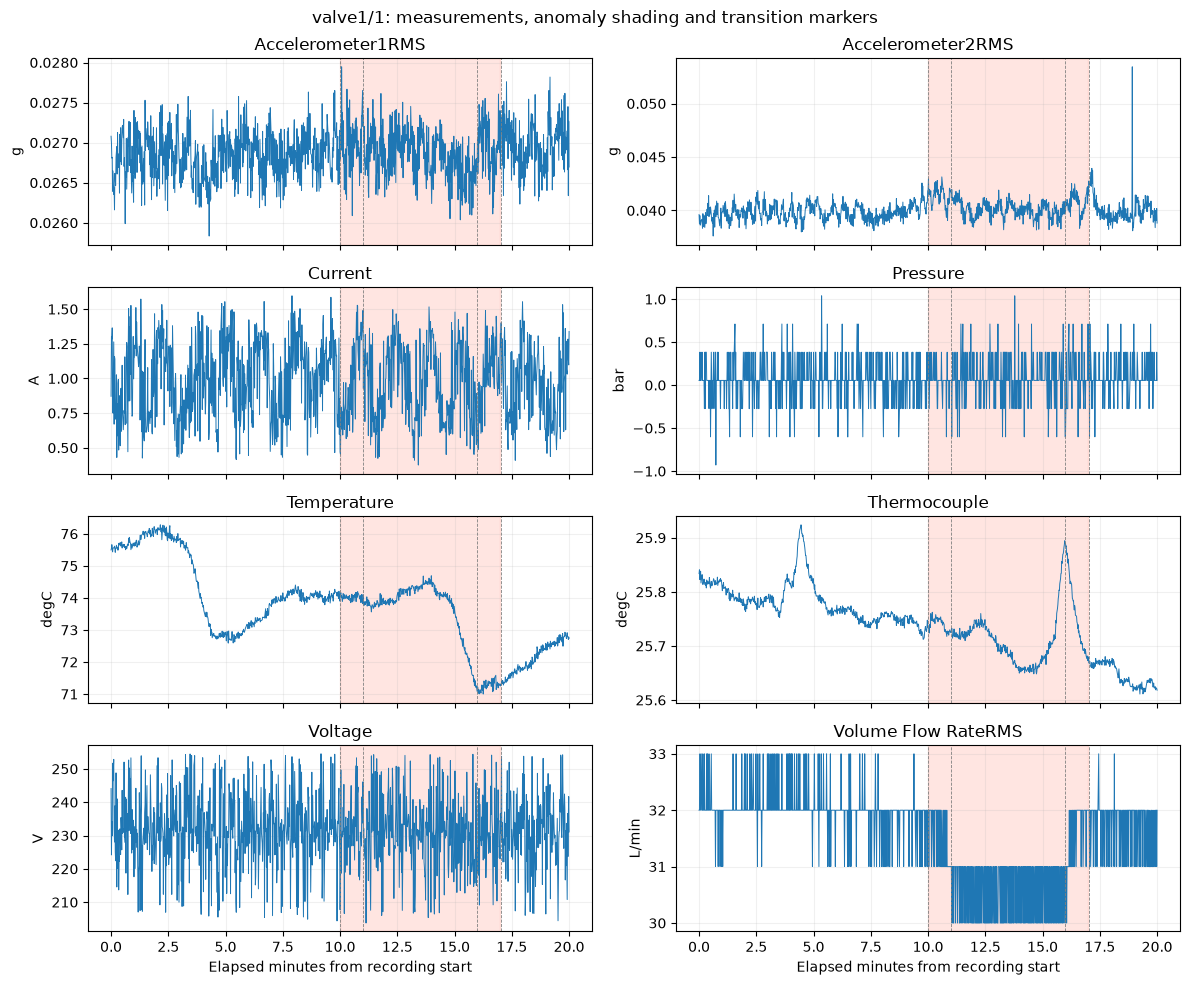

In [5]:
example_id = settings["example_recording"]
example = recordings[example_id]
labels = annotations[example_id]
origin = example.timestamp.iloc[0]
elapsed = (example.timestamp - origin).dt.total_seconds() / 60
connected_groups = example.timestamp.diff().gt(pd.Timedelta(settings["gap_threshold"])).cumsum()
fig, axes = plt.subplots(4, 2, figsize=(12, 10), sharex=True)
for ax, name in zip(axes.flat, names):
    for _, positions in example.groupby(connected_groups).groups.items():
        ax.plot(elapsed.loc[positions], example.loc[positions, name], linewidth=.7)
    for event in event_runs[example_id].itertuples():
        ax.axvspan((event.start - origin).total_seconds() / 60,
                   (event.last - origin).total_seconds() / 60, color="tomato", alpha=.16)
    for timestamp in labels.loc[labels.changepoint.eq(1), "timestamp"]:
        ax.axvline((timestamp - origin).total_seconds() / 60, color="grey", linestyle="--", linewidth=.6)
    ax.set(title=name, ylabel=units[name])
for ax in axes[-1]:
    ax.set_xlabel("Elapsed minutes from recording start")
fig.suptitle(f"{example_id}: measurements, anomaly shading and transition markers", fontsize=12)
fig.tight_layout()
plt.show()

**Observed in this example.** Flow moves from around 32 L/min toward 30–31 L/min during much
of the labelled interval, then rises again. Accelerometer2RMS changes more visibly than
Accelerometer1RMS. Current and voltage retain substantial short-term variation, while the motor
and fluid temperature traces also change outside the labelled interval.

The label applies to the experiment even when a particular channel shows little response.
This motivates both individual-signal and relationship checks; it does not justify treating every
sensor reading in the shaded interval as independently faulty.

## 5. Distributions and measurement resolution
We first compare the initial prefix with the positive-label observations **within the same experiment**.
Histograms are normalised separately, so they show distribution shape rather than the prevalence of
anomalies. They are descriptive; adjacent points are not independent replicates.

The table uses all initial prefixes, but summarises each recording separately before comparing medians.
It therefore exposes differences between experiments without allowing the longest recording to dominate.

,min,median,max,sd,unique
measurement,,,,,
Accelerometer1RMS,0.02583,0.02684,0.02765,0.00030,561
Accelerometer2RMS,0.03761,0.03976,0.04257,0.00076,564
Current,0.41527,1.03695,1.59619,0.28184,571
Pressure,-0.92907,0.05471,1.03849,0.25151,7
Temperature,72.58970,74.08930,76.28010,1.14706,563
Thermocouple,25.71240,25.77455,25.92400,0.03763,445
Voltage,204.37200,231.42400,254.52000,10.95748,566
Volume Flow RateRMS,31.00000,32.00000,33.00000,0.43970,28


,smallest_recording_median,largest_recording_median,fewest_distinct_in_prefix,median_within_recording_sd
measurement,,,,
Accelerometer1RMS,0.02641,0.24843,103,0.00048
Accelerometer2RMS,0.03905,0.29108,103,0.00127
Current,0.92710,2.60062,104,0.28015
Pressure,0.05471,0.05471,5,0.25788
Temperature,67.21850,93.89940,104,0.43594
Thermocouple,22.07755,30.94865,86,0.02353
Voltage,227.18400,231.58500,104,10.79264
Volume Flow RateRMS,32.00000,128.00000,12,0.47490


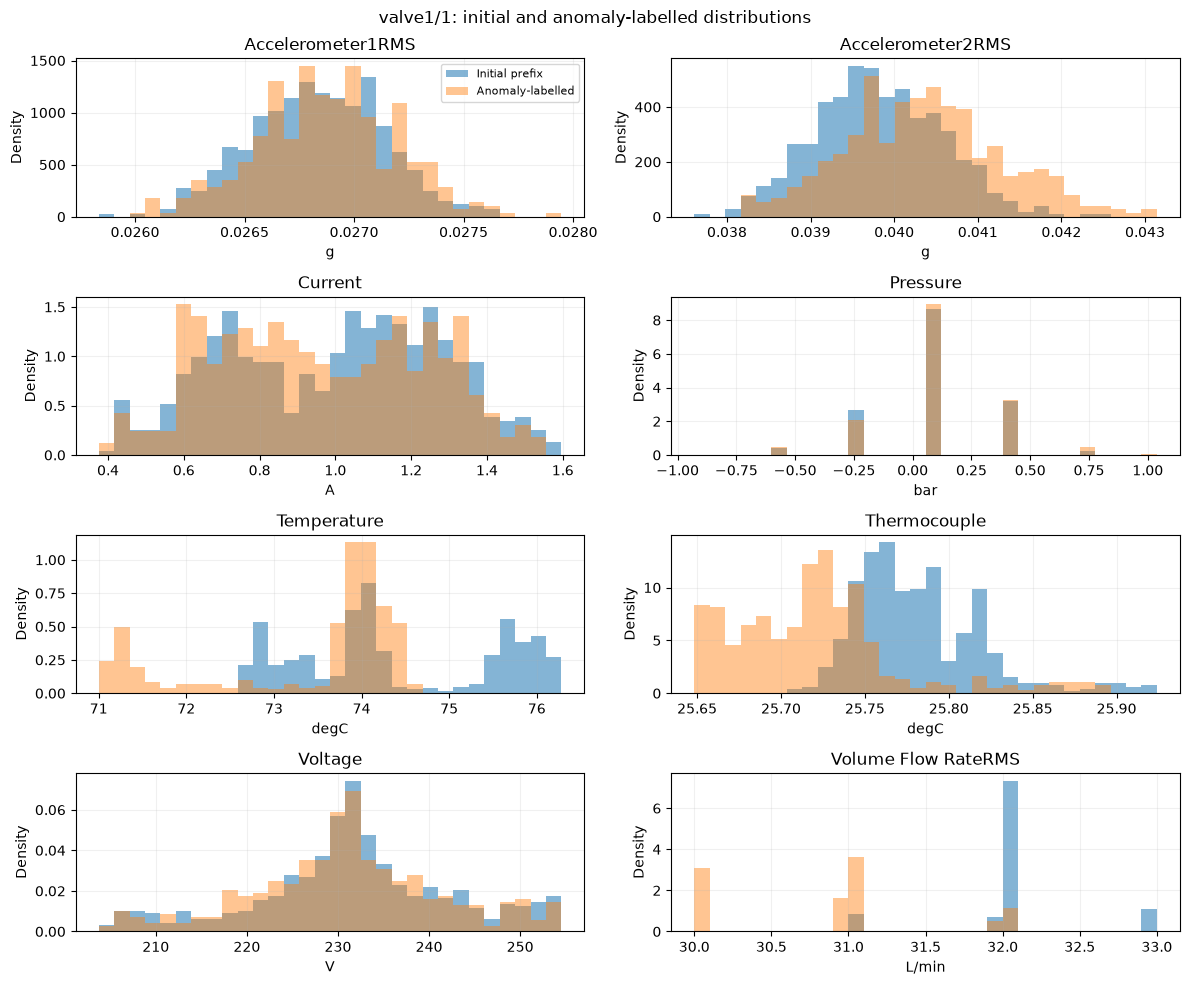

In [6]:
prefix_profiles = signal_profile(pd.concat(prefixes.values(), ignore_index=True), METRICS)
display(prefix_profiles.loc[prefix_profiles.entity_id.eq(example_id),
        ["measurement", "min", "median", "max", "sd", "unique"]].set_index("measurement").round(5))
baseline_spread = prefix_profiles.groupby("measurement").agg(
    smallest_recording_median=("median", "min"),
    largest_recording_median=("median", "max"),
    fewest_distinct_in_prefix=("unique", "min"),
    median_within_recording_sd=("sd", "median"))
display(baseline_spread.round(5))

fig, axes = plt.subplots(4, 2, figsize=(12, 10))
positive = example.loc[labels.anomaly.eq(1)]
for ax, name in zip(axes.flat, names):
    first = prefixes[example_id][name].dropna()
    second = positive[name].dropna()
    bins = np.histogram_bin_edges(np.r_[first, second], bins=30)
    ax.hist(first, bins=bins, density=True, alpha=.55, label="Initial prefix")
    ax.hist(second, bins=bins, density=True, alpha=.45, label="Anomaly-labelled")
    ax.set(title=name, xlabel=units[name], ylabel="Density")
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"{example_id}: initial and anomaly-labelled distributions")
fig.tight_layout()
plt.show()

A distribution difference describes an observed response, not detector accuracy. A pooled mean and
standard deviation may be particularly unhelpful for coarse or multimodal measurements. Also, a
recording-level label does not establish which individual signal values are abnormal.

## 6. Does the anomaly-free file represent every experiment?
The plot below places each recording's initial median beside the separate anomaly-free median.
Each point is one recording, not one sensor sample. Colours denote source experiment families;
family names are used only for interpretation, not proposed predictors.

Do not standardise these differences away before understanding them: changing operating conditions
and the intervention itself can both shift measurements. In particular, the separate normal recording
need not be a transferable reference for the valve experiments.

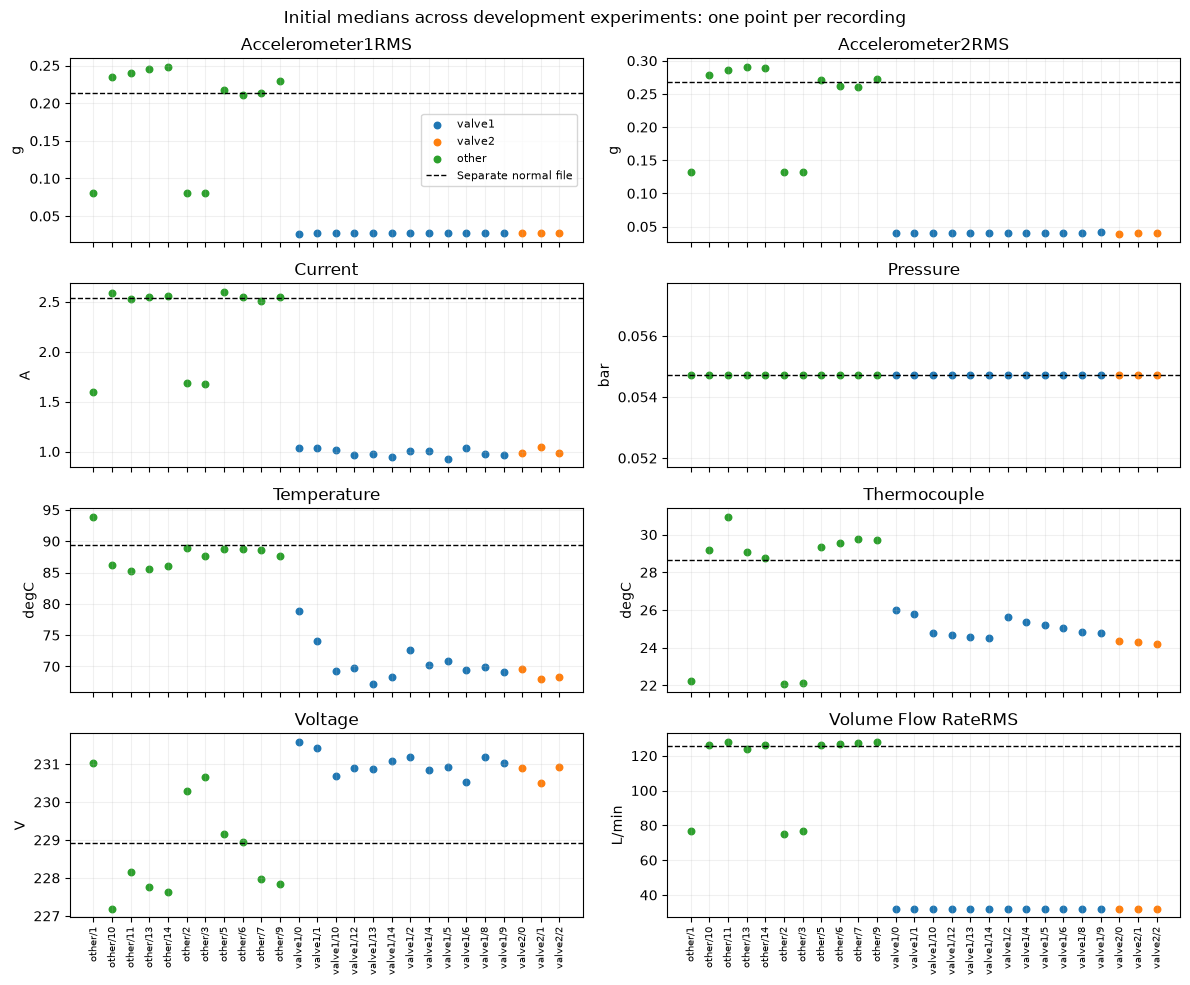

Separate normal flow median: 125.677 L/min.
Development prefix flow medians: 32.000–128.000 L/min.


In [7]:
reference_id = "anomaly-free/anomaly-free"
reference_medians = prefixes[reference_id][names].median()
initial_medians = pd.DataFrame({key: frame[names].median()
                               for key, frame in prefixes.items() if key != reference_id}).T
family_colours = {"valve1": "tab:blue", "valve2": "tab:orange", "other": "tab:green"}
fig, axes = plt.subplots(4, 2, figsize=(12, 10), sharex=True)
for ax, name in zip(axes.flat, names):
    for family, colour in family_colours.items():
        positions = [i for i, key in enumerate(initial_medians.index) if key.startswith(family + "/")]
        ax.scatter(positions, initial_medians.iloc[positions][name], s=22, color=colour, label=family)
    ax.axhline(reference_medians[name], color="black", linestyle="--", linewidth=1,
               label="Separate normal file")
    ax.set(title=name, ylabel=units[name])
axes[0, 0].legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xticks(range(len(initial_medians)))
    ax.set_xticklabels(initial_medians.index, rotation=90, fontsize=7)
fig.suptitle("Initial medians across development experiments: one point per recording")
fig.tight_layout()
plt.show()
print(f"Separate normal flow median: {reference_medians['Volume Flow RateRMS']:.3f} L/min.")
print(f"Development prefix flow medians: {initial_medians['Volume Flow RateRMS'].min():.3f}–"
      f"{initial_medians['Volume Flow RateRMS'].max():.3f} L/min.")

**Implication.** The observed reference differences prevent treating the separate normal file as
interchangeable with every experiment. There is no documented command channel to explain these regimes.
We should compare explicit reference choices in Notebook 02. Experiment identity can keep analyses
separate, but is not an explanatory physical predictor and cannot supply a baseline for an unseen regime.

## 7. Temporal dependence, drift and periodicity
**Question:** does recent history matter, and is the sampling adequate to assess it?

A row shift is not always a one-second lag. We report the longest uninterrupted one-second segment
first. Then, for a longer descriptive view, use five-second means with at least four observations.
Insufficient bins remain missing. A mean is available only at its interval end; the plots below use
that time convention. This aggregation changes the signal and can smooth short events; it is not yet
the modelling resolution.

The ACF uses the longest fully supported regular segment of the initial prefix only, with at most
one quarter of its length in lags. We use the standard demeaned covariance calculation through
[statsmodels](https://www.statsmodels.org/v0.14.6/generated/statsmodels.tsa.stattools.acf.html).
No IID significance bands or automatic stationarity decisions are made.

Longest native one-second prefix segment: {'start': Timestamp('2020-03-09 10:34:40'), 'end': Timestamp('2020-03-09 10:35:03'), 'samples': 24}


,measurement,start,end,samples,usable_bins,acf_5seconds
0,Accelerometer1RMS,2020-03-09 10:34:40,2020-03-09 10:44:30,119,119,0.454
1,Accelerometer2RMS,2020-03-09 10:34:40,2020-03-09 10:44:30,119,119,0.479
2,Current,2020-03-09 10:34:40,2020-03-09 10:44:30,119,119,0.657
3,Pressure,2020-03-09 10:34:40,2020-03-09 10:44:30,119,119,-0.060
4,Temperature,2020-03-09 10:34:40,2020-03-09 10:44:30,119,119,0.992
5,Thermocouple,2020-03-09 10:34:40,2020-03-09 10:44:30,119,119,0.961
6,Voltage,2020-03-09 10:34:40,2020-03-09 10:44:30,119,119,-0.005
7,Volume Flow RateRMS,2020-03-09 10:34:40,2020-03-09 10:44:30,119,119,0.491


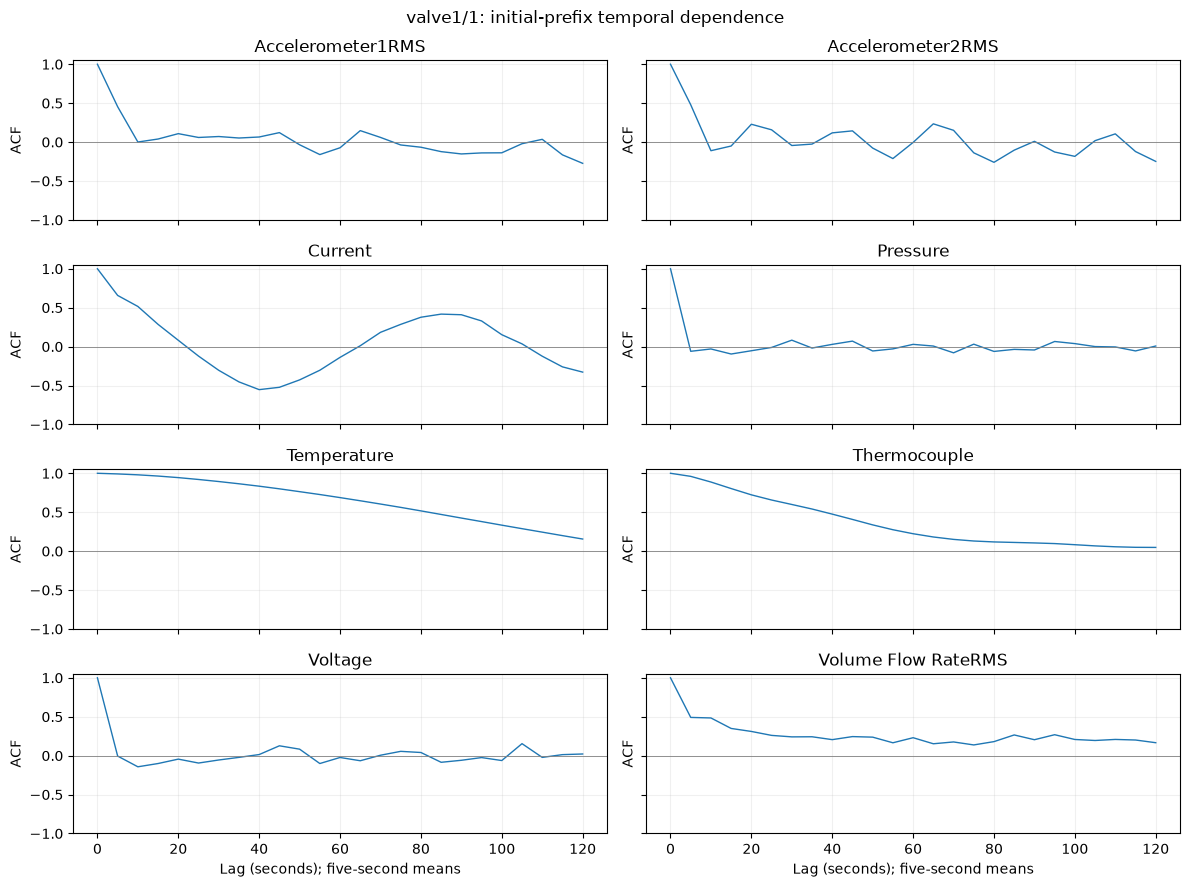

,minimum_samples,measurement,usable_bins,segment_bins,acf_5seconds
0,3,Temperature,120,120,0.992
1,3,Thermocouple,120,120,0.963
2,4,Temperature,119,119,0.992
3,4,Thermocouple,119,119,0.961
4,5,Temperature,91,4,NaN
5,5,Thermocouple,91,4,NaN


In [8]:
native_acf, native_info = segment_acf(
    prefixes[example_id].set_index("timestamp")["Temperature"], "1s", 60)
print("Longest native one-second prefix segment:", native_info)
five_second, support = aggregate_gauges(prefixes[example_id], names, "5s", 4)
five_second.index += pd.Timedelta(seconds=5)  # Completed-bin availability.
acf_rows = []
curves = {}
for name in names:
    curves[name], info = segment_acf(five_second[name], "5s", 24)
    acf_rows.append({"measurement": name, **info,
                     "usable_bins": int(five_second[name].notna().sum()),
                     "acf_5seconds": curves[name].acf.iloc[1] if len(curves[name]) > 1 else np.nan})
acf_summary = pd.DataFrame(acf_rows)
display(acf_summary.round(3))

fig, axes = plt.subplots(4, 2, figsize=(12, 9), sharex=True, sharey=True)
for ax, name in zip(axes.flat, names):
    curve = curves[name]
    ax.plot(curve.lag_steps * 5, curve.acf, linewidth=1)
    ax.axhline(0, color="grey", linewidth=.6)
    ax.set(title=name, ylabel="ACF", ylim=(-1, 1.05))
for ax in axes[-1]:
    ax.set_xlabel("Lag (seconds); five-second means")
fig.suptitle(f"{example_id}: initial-prefix temporal dependence")
fig.tight_layout()
plt.show()

sensitivity_rows = []
for minimum in (3, 4, 5):
    aggregate, counts = aggregate_gauges(prefixes[example_id], names, "5s", minimum)
    for name in ("Temperature", "Thermocouple"):
        curve, info = segment_acf(aggregate[name], "5s", 24)
        sensitivity_rows.append({"minimum_samples": minimum, "measurement": name,
                                 "usable_bins": int(aggregate[name].notna().sum()),
                                 "segment_bins": info["samples"],
                                 "acf_5seconds": curve.acf.iloc[1] if len(curve) > 1 else np.nan})
display(pd.DataFrame(sensitivity_rows).round(3))

**Observed:** the example's five-second temperature ACF decays slowly, while pressure and voltage
have little lag-one dependence at that resolution. Current shows an oscillating ACF. These findings
describe one short prefix and require checks across other recordings before choosing a model.

Strong ACF can arise from drift as well as predictable fluctuations; it does not establish seasonality
or stationarity. The three- and four-sample support rules give similar thermal ACFs here. Requiring
five observations leaves very short uninterrupted segments, so the reported ACF is undefined.
That loss of evidence is preferable to silently filling gaps.

These short experiments cannot substantiate daily or weekly seasonality. Repetition within a trace
may reflect equipment dynamics, but requires stable repeated cycles and validation in other recordings.
No seasonal decomposition is justified here.

## 8. Relationships between sensors
Compare rank correlations in the same example before and during its labelled anomaly.
Spearman correlation is a descriptive measure of co-movement, not proof of causation or independence.
The matrices use paired observations; ties in coarse channels and temporal dependence limit inference.

We then inspect a small set of physically interpretable pairs across all initial prefixes. These are
illustrative checks, not a feature-selection exercise. We do not pool unrelated experiments to obtain
an apparently stronger correlation.

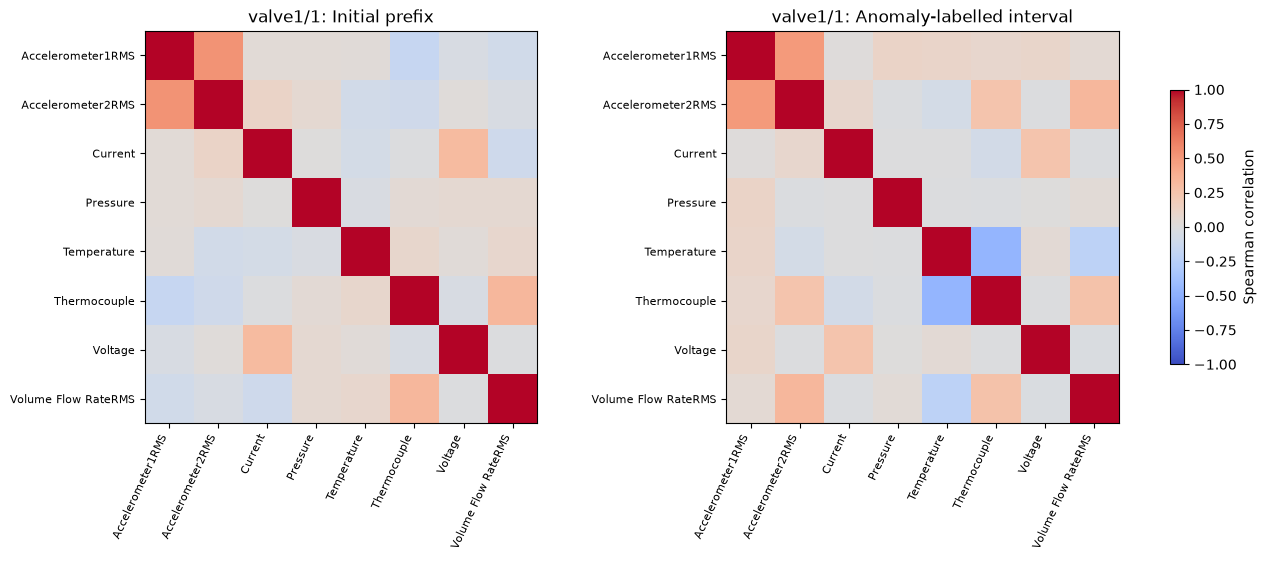

,,valid_recordings,min_spearman,median_spearman,max_spearman
first,second,,,,
Accelerometer1RMS,Accelerometer2RMS,27,-0.741,0.502,0.821
Current,Voltage,27,0.254,0.337,0.505
Pressure,Volume Flow RateRMS,27,-0.096,-0.020,0.058
Temperature,Thermocouple,27,-0.834,-0.088,0.628


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained")
for ax, frame, title in zip(axes, (prefixes[example_id], positive),
                           ("Initial prefix", "Anomaly-labelled interval")):
    correlation = frame[names].corr(method="spearman")
    picture = ax.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(names)), names, rotation=65, ha="right", fontsize=8)
    ax.set_yticks(range(len(names)), names, fontsize=8)
    ax.set_title(f"{example_id}: {title}")
    ax.grid(False)
fig.colorbar(picture, ax=axes, shrink=.7, label="Spearman correlation")
plt.show()

pairs = [("Accelerometer1RMS", "Accelerometer2RMS"),
         ("Current", "Voltage"), ("Pressure", "Volume Flow RateRMS"),
         ("Temperature", "Thermocouple")]
relationships = []
for identifier, frame in prefixes.items():
    result = relationship_report(frame, pairs)
    result["recording"] = identifier
    relationships.append(result)
relationships = pd.concat(relationships, ignore_index=True)
relationship_summary = relationships.groupby(["first", "second"]).agg(
    valid_recordings=("spearman", "count"),
    min_spearman=("spearman", "min"), median_spearman=("spearman", "median"),
    max_spearman=("spearman", "max"))
display(relationship_summary.round(3))

**Interpretation.** Relationships that differ across recordings are candidates for conditional
monitoring, not universal equations. Shared trends or a common intervention can also create
correlation. A multivariate detector will need a stated fitting population and must be compared
against individual-signal baselines; this notebook does not establish that it will be better.

## 9. Handover to Notebook 02
Keep all eight measurements as assessment candidates. The table connects each measurement to its
observed support and a specific modelling caution. Nothing is dropped merely for having weak
correlation in one experiment.

The immediate next question is **which reference behaviour transfers across these recordings?**
Start with interpretable individual-signal references and inspect temporal residuals before adding a
multivariate comparison. Keep the separate normal recording and initial prefixes as distinct candidate
reference sources, rather than silently mixing them.

In [10]:
cautions = {
    "Accelerometer1RMS": "Monitor amplitude; do not infer a vibration spectrum from RMS.",
    "Accelerometer2RMS": "Compare both vibration channels; assess cross-recording shifts.",
    "Current": "Preserve noisy native variation; compare with electrical context.",
    "Pressure": "Coarse levels and negative values; verify meaning before physical limits.",
    "Temperature": "Strong persistence may include drift; consider limited causal history.",
    "Thermocouple": "Separate fluid from motor temperature; check drift and regime transfer.",
    "Voltage": "Retain as a measurement; do not assume a fixed supply distribution.",
    "Volume Flow RateRMS": "Large reference-level differences; do not pool operating regimes.",
}
handover = baseline_spread.join(acf_summary.set_index("measurement")[["acf_5seconds"]])
handover["unit"] = pd.Series(units)
handover["next_step"] = pd.Series(cautions)
display(handover[["unit", "smallest_recording_median", "largest_recording_median",
                  "fewest_distinct_in_prefix", "acf_5seconds", "next_step"]].round(4))
print("ACF entries describe only the configured example, not the whole dataset.")
for filename, table in {
    "recording_quality.csv": timing, "signal_profiles.csv": profiles,
    "label_audit.csv": label_audit, "initial_prefix_profiles.csv": prefix_profiles,
    "relationship_summary.csv": relationship_summary, "handover.csv": handover,
}.items():
    table.to_csv(OUTPUT / filename, index=True)
versions = {package: version(package) for package in ("numpy", "pandas", "matplotlib", "statsmodels", "nbclient")}
run_manifest = {
    "source_commit": settings["source_commit"],
    "opened_recordings": list(recordings),
    "reserved_recordings": sorted(reserved),
    "source_files": settings["files"],
    "python": platform.python_version(), "packages": versions,
    "gap_threshold": settings["gap_threshold"], "acf_frequency": "5s", "acf_minimum_samples": 4,
}
(OUTPUT / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2))
assert set(run_manifest["opened_recordings"]).isdisjoint(run_manifest["reserved_recordings"])
print("Saved small diagnostic tables and provenance under outputs/skab_assessment (Git-ignored).")
print("Environment:", versions)

,unit,smallest_recording_median,largest_recording_median,fewest_distinct_in_prefix,acf_5seconds,next_step
measurement,,,,,,
Accelerometer1RMS,g,0.0264,0.2484,103,0.4543,Monitor amplitude; do not infer a vibration spectrum from RMS.
Accelerometer2RMS,g,0.0390,0.2911,103,0.4794,Compare both vibration channels; assess cross-recording shifts.
Current,A,0.9271,2.6006,104,0.6575,Preserve noisy native variation; compare with electrical context.
Pressure,bar,0.0547,0.0547,5,-0.0605,Coarse levels and negative values; verify meaning before physical limits.
Temperature,degC,67.2185,93.8994,104,0.9917,Strong persistence may include drift; consider limited causal history.
Thermocouple,degC,22.0776,30.9486,86,0.9605,Separate fluid from motor temperature; check drift and regime transfer.
Voltage,V,227.1840,231.5850,104,-0.0052,Retain as a measurement; do not assume a fixed supply distribution.
Volume Flow RateRMS,L/min,32.0000,128.0000,12,0.4912,Large reference-level differences; do not pool operating regimes.


ACF entries describe only the configured example, not the whole dataset.
Saved small diagnostic tables and provenance under outputs/skab_assessment (Git-ignored).
Environment: {'numpy': '2.3.5', 'pandas': '2.3.3', 'matplotlib': '3.11.2', 'statsmodels': '0.14.6', 'nbclient': '0.11.0'}


**Decisions carried forward**

- Keep recordings separate, preserve timestamps and make gaps explicit. Reset future model history at
  boundaries; do not interpolate through missing stretches merely to obtain a regular matrix.
- Retain all eight candidate measurements. Separate source-specific meanings from generic sampling,
  distribution and dependence calculations. There are no known command groups to condition on.
- Freeze these eight test recordings. Choose fitting/calibration rules on development experiments only.
  Any use of a new experiment's initial prefix must be declared in advance and chronological; its future
  labels cannot be used to choose the prefix at deployment.
- Compare normal-reference transfer explicitly. The anomaly-free recording is a candidate reference,
  not evidence that all labelled-normal prefixes share its distribution.
- Later evaluate alert burden and detection delay per experiment, with annotation uncertainty.
  Development labels are not a complete industrial fault taxonomy. A changepoint marker is not necessarily
  a separate failure, and detecting an intervention is not the same as predicting a future failure.

**Limits.** One controlled testbed and short recordings can support testing data contracts and
univariate/multivariate detection methods. They cannot establish generalisation to other companies,
long-term drift, seasonal behaviour or field false-alarm rates. A later, longer operational dataset
is needed for those questions. Passing data-quality checks is not proof of realism.

**Sources.** Measurement semantics and intended interventions: the pinned SKAB repository linked above
(dataset documentation). Dataset citation: Katser & Kozitsin (2020),
[Skoltech Anomaly Benchmark](https://doi.org/10.34740/KAGGLE/DSV/1693952).
ACF implementation: statsmodels documentation linked in Section 7 (technical documentation).
Experiment selection, support thresholds and interpretations in this notebook are our analytical choices,
not official benchmark requirements.